# Phase 05A: KD Improvement Entry & Experiment Lock

## Mục tiêu

Phase 05A không huấn luyện mô hình. Notebook này:

1. xác minh ba aggregate chính thức của Phase 4;
2. tổng hợp paired improvement của ba cặp Teacher–Student;
3. khóa cặp anchor và loss ablation đầu tiên;
4. khóa budget, tiêu chí chọn và thứ tự triển khai;
5. duy trì Held-out Test `SEALED`;
6. authorize Phase 05B feature-alignment preflight.

## Quyết định khoa học được khóa

Nhánh đầu tiên dùng **Teacher A CLIP ViT-B/32 → S1 MobileNetV3-Large** vì:

- Logit-KD đã tái lập thành công trên ba seed;
- hai phía dùng cùng vocabulary/decoder-token semantics;
- visual memory đều có dạng `[B,49,256]`;
- feature KD không cần nội suy 196→49 token như Teacher C → S3;
- phù hợp để tách riêng đóng góp của feature loss.

Hai arm mới:

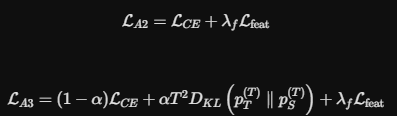


với `T=4`, `α=0.5`, `λf=0.1`. Feature loss dùng normalized MSE,
Teacher được stop-gradient.

## Kaggle inputs

1. Phase 04F Teacher A → S1 three-seed aggregate.
2. Phase 04M Teacher B → S2 three-seed aggregate.
3. Phase 04S Teacher C → S3 three-seed aggregate.

CPU là đủ, Internet Off, không gắn dataset ảnh hoặc checkpoint.



## Cell 1 — Khóa authorization và ba aggregate Phase 4

Tìm đúng một complete marker cho mỗi cặp, xác minh experiment ID, seed set,
reproduction status, Validation-only selection và Test boundary.

**Đầu ra dự kiến:** `3 / 3 VERIFIED`, Phase 5 authorization `VERIFIED`.


In [1]:
import csv
import hashlib
import json
import math
import os
import time
from datetime import datetime, timezone
from pathlib import Path


CELL_STARTED_AT = time.perf_counter()
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path(
    "/kaggle/working//phase5_kd_improvement_entry"
)
AUDIT_DIR = OUTPUT_ROOT / "audits"
CONFIG_DIR = OUTPUT_ROOT / "configs"
RESULT_DIR = OUTPUT_ROOT / "results"
FIGURE_DIR = OUTPUT_ROOT / "figures"
MANIFEST_DIR = OUTPUT_ROOT / "manifests"
for directory in [
    OUTPUT_ROOT, AUDIT_DIR, CONFIG_DIR, RESULT_DIR,
    FIGURE_DIR, MANIFEST_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

SEEDS = (42, 123, 2026)
PAIR_SPECS = {
    "A_S1": {
        "experiment_id": "P4A_A_S1_LOGIT",
        "marker_name": (
            "PHASE4_TEACHER_A_S1_LOGIT_KD_"
            "THREE_SEED_AGGREGATE_COMPLETE.json"
        ),
        "teacher": "Teacher A — CLIP ViT-B/32",
        "student": "S1 — MobileNetV3-Large",
        "method": "response/logit KD",
    },
    "B_S2": {
        "experiment_id": "P4B_B_S2_SEQKD",
        "marker_name": (
            "PHASE4_TEACHER_B_S2_SEQUENCE_KD_"
            "THREE_SEED_AGGREGATE_COMPLETE.json"
        ),
        "teacher": "Teacher B — BLIP Base",
        "student": "S2 — MobileViT-S",
        "method": "sequence KD",
    },
    "C_S3": {
        "experiment_id": "P4C_C_S3_LOGIT",
        "marker_name": (
            "PHASE4_TEACHER_C_S3_LOGIT_KD_"
            "THREE_SEED_AGGREGATE_COMPLETE.json"
        ),
        "teacher": "Teacher C — SigLIP ViT-B/16",
        "student": "S3 — TinyViT-5M",
        "method": "direct response/logit KD",
    },
}


def now_utc():
    return datetime.now(timezone.utc).isoformat()


def read_json(path):
    with Path(path).open("r", encoding="utf-8") as handle:
        return json.load(handle)


def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    os.replace(temporary, path)


def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


def exactly_one(name):
    matches = sorted(INPUT_ROOT.rglob(name))
    assert len(matches) == 1, (
        f"Cần đúng một {name}; tìm thấy {len(matches)}: {matches}"
    )
    return matches[0].resolve()


def resolve_inside(root, relative_path):
    root = Path(root).resolve()
    target = (root / relative_path).resolve()
    assert target.is_relative_to(root), (root, target)
    return target


AUTHORIZATION_PATH = exactly_one(
    "PHASE5_KD_IMPROVEMENT_ENTRY_AUTHORIZED.json"
)
authorization = read_json(AUTHORIZATION_PATH)
assert authorization["status"] == "authorized"
assert authorization["source_experiment"] == "P4C_C_S3_LOGIT"
assert authorization["source_reproduction_status"] == "passed"
assert len(authorization["completed_reproduction_pairs"]) == 3
assert authorization["test_set_status"] == "sealed"
assert authorization["test_set_used"] is False

PAIRS = {}
for pair_id, spec in PAIR_SPECS.items():
    marker_path = exactly_one(spec["marker_name"])
    marker = read_json(marker_path)
    assert marker["status"] == "complete"
    assert marker["experiment_id"] == spec["experiment_id"]
    assert marker["seeds"] == list(SEEDS)
    assert marker["protocol_consistency"] == "exact"
    assert marker["reproduction_status"] == "passed"
    assert marker["manifest_verification"] == "all_passed"
    assert marker["selection_split"] == "validation"
    assert marker["test_set_status"] == "sealed"
    assert marker["test_set_used"] is False
    PAIRS[pair_id] = {
        "root": marker_path.parent,
        "marker_path": marker_path,
        "marker": marker,
        "spec": spec,
    }

write_json(
    AUDIT_DIR / "phase5a_cell01_authorization.json",
    {
        "audit_version": "phase5a_cell01_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "phase5_authorization": "verified",
        "phase4_aggregates": "3 / 3 verified",
        "experiments": [
            spec["experiment_id"] for spec in PAIR_SPECS.values()
        ],
        "seeds": list(SEEDS),
        "dataset_read": False,
        "caption_read": False,
        "checkpoint_payload_read": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05A CELL 1 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Phase 5 authorization     : VERIFIED")
print("Phase 4 aggregates        : 3 / 3 VERIFIED")
print("Seeds                     : 42 / 123 / 2026")
print("Selection split           : Validation")
print("Dataset/caption read      : False / False")
print("Checkpoint payload read   : False")
print("Test Set status           : SEALED")
print("Progress                  : 1 / 6 cells passed")
print("Next                      : verify source manifests")


PHASE 05A CELL 1 STATUS
Status                    : PASSED
Phase 5 authorization     : VERIFIED
Phase 4 aggregates        : 3 / 3 VERIFIED
Seeds                     : 42 / 123 / 2026
Selection split           : Validation
Dataset/caption read      : False / False
Checkpoint payload read   : False
Test Set status           : SEALED
Progress                  : 1 / 6 cells passed
Next                      : verify source manifests


## Cell 2 — Xác minh manifest và summary nguồn

Tính lại SHA-256 cho toàn bộ 39 artifact của ba aggregate; kiểm tra
SHA256SUMS, summary/conclusion reference và Phase 5 authorization reference.

**Đầu ra dự kiến:** `39 / 39 VERIFIED`.


In [2]:
CELL_STARTED_AT = time.perf_counter()
SOURCE_MANIFEST_COUNTS = {}
SOURCE_SUMMARIES = {}

for pair_id, pair in PAIRS.items():
    root = pair["root"]
    marker = pair["marker"]
    manifest_path = resolve_inside(
        root, marker["manifest"]["csv"]["relative_path"]
    )
    assert sha256_file(manifest_path) == (
        marker["manifest"]["csv"]["sha256"]
    )
    rows = list(csv.DictReader(
        manifest_path.open("r", encoding="utf-8", newline="")
    ))
    assert len(rows) == int(marker["manifest_rows"]) == 13
    expected_sums = []
    for row in rows:
        artifact = resolve_inside(root, row["relative_path"])
        assert artifact.stat().st_size == int(row["size_bytes"])
        assert sha256_file(artifact) == row["sha256"]
        expected_sums.append(
            f'{row["sha256"]}  {row["relative_path"]}'
        )
    sums_path = resolve_inside(
        root, marker["manifest"]["sha256sums"]["relative_path"]
    )
    assert sha256_file(sums_path) == (
        marker["manifest"]["sha256sums"]["sha256"]
    )
    actual_sums = [
        line.strip()
        for line in sums_path.read_text(
            encoding="utf-8"
        ).splitlines()
        if line.strip()
    ]
    assert actual_sums == expected_sums

    for role in ("summary", "conclusion"):
        target = resolve_inside(
            root, marker[role]["relative_path"]
        )
        assert sha256_file(target) == marker[role]["sha256"]
    summary_path = resolve_inside(
        root, marker["summary"]["relative_path"]
    )
    summary = read_json(summary_path)
    assert summary["experiment_id"] == marker["experiment_id"]
    assert summary["seeds"] == list(SEEDS)
    assert len(summary["per_seed"]) == 3
    assert summary["selection_split"] == "validation"
    assert summary["test_set_status"] == "sealed"
    assert summary["test_set_used"] is False
    SOURCE_SUMMARIES[pair_id] = summary
    SOURCE_MANIFEST_COUNTS[pair_id] = len(rows)

assert SOURCE_MANIFEST_COUNTS == {
    "A_S1": 13, "B_S2": 13, "C_S3": 13
}
assert sum(SOURCE_MANIFEST_COUNTS.values()) == 39

source_s_marker = PAIRS["C_S3"]["marker"]
auth_ref = source_s_marker["next_authorization"]
assert resolve_inside(
    PAIRS["C_S3"]["root"], auth_ref["relative_path"]
) == AUTHORIZATION_PATH
assert sha256_file(AUTHORIZATION_PATH) == auth_ref["sha256"]

write_json(
    AUDIT_DIR / "phase5a_cell02_source_integrity.json",
    {
        "audit_version": "phase5a_cell02_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "source_manifest_rows": SOURCE_MANIFEST_COUNTS,
        "total_source_manifest_rows": 39,
        "summary_references": "3 / 3 verified",
        "conclusion_references": "3 / 3 verified",
        "authorization_reference": "verified",
        "checkpoint_payload_read": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05A CELL 2 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Source manifest rows      :", SOURCE_MANIFEST_COUNTS)
print("Total rows verified       : 39 / 39")
print("Summaries / conclusions   : 3 / 3 VERIFIED")
print("Authorization reference   : VERIFIED")
print("Checkpoint payload read   : False")
print("Test Set status           : SEALED")
print("Progress                  : 2 / 6 cells passed")
print("Next                      : cross-pair comparison")


PHASE 05A CELL 2 STATUS
Status                    : PASSED
Source manifest rows      : {'A_S1': 13, 'B_S2': 13, 'C_S3': 13}
Total rows verified       : 39 / 39
Summaries / conclusions   : 3 / 3 VERIFIED
Authorization reference   : VERIFIED
Checkpoint payload read   : False
Test Set status           : SEALED
Progress                  : 2 / 6 cells passed
Next                      : cross-pair comparison


## Cell 3 — So sánh chéo ba cặp Phase 4

Xuất bảng paired delta theo đúng baseline cùng Student và cùng seed.

> Lưu ý: absolute CIDEr-D giữa ba hàng không cô lập riêng ảnh hưởng của
> Teacher vì Student và KD channel cũng khác nhau. Bảng này dùng để mô tả
> hiệu quả reproduction của từng cặp, không dùng để tuyên bố Teacher nào
> tốt nhất.


In [3]:
CELL_STARTED_AT = time.perf_counter()
PAIR_ROWS = []
for pair_id, pair in PAIRS.items():
    summary = SOURCE_SUMMARIES[pair_id]
    aggregate = summary["aggregate"]
    paired = aggregate["CIDEr-D"]["paired_delta"]
    row = {
        "pair_id": pair_id,
        "experiment_id": pair["marker"]["experiment_id"],
        "teacher": pair["spec"]["teacher"],
        "student": pair["spec"]["student"],
        "method": pair["spec"]["method"],
        "baseline_cider_mean": (
            aggregate["CIDEr-D"]["baseline"]["mean"]
        ),
        "kd_cider_mean": aggregate["CIDEr-D"]["kd"]["mean"],
        "paired_cider_delta_mean": paired["mean"],
        "paired_cider_delta_sample_std": paired["sample_std"],
        "relative_cider_gain_percent": aggregate[
            "relative_cider_gain_percent"
        ]["mean"],
        "baseline_bleu4_mean": (
            aggregate["BLEU-4"]["baseline"]["mean"]
        ),
        "kd_bleu4_mean": aggregate["BLEU-4"]["kd"]["mean"],
        "paired_bleu4_delta_mean": (
            aggregate["BLEU-4"]["paired_delta"]["mean"]
        ),
        "baseline_validation_ce_mean": (
            aggregate["validation_ce"]["baseline"]["mean"]
        ),
        "kd_validation_ce_mean": (
            aggregate["validation_ce"]["kd"]["mean"]
        ),
        "paired_validation_ce_delta_mean": (
            aggregate["validation_ce"]["paired_delta"]["mean"]
        ),
        "cider_wins": summary["paired_consistency"]["cider_wins"],
    }
    assert all(
        math.isfinite(value)
        for value in row.values()
        if isinstance(value, float)
    )
    assert row["paired_cider_delta_mean"] >= 0.001
    PAIR_ROWS.append(row)

CROSS_PAIR_CSV = RESULT_DIR / (
    "phase5a_phase4_cross_pair_comparison.csv"
)
with CROSS_PAIR_CSV.open(
    "w", encoding="utf-8", newline=""
) as handle:
    writer = csv.DictWriter(
        handle, fieldnames=list(PAIR_ROWS[0])
    )
    writer.writeheader()
    writer.writerows(PAIR_ROWS)

CROSS_PAIR_JSON = RESULT_DIR / (
    "phase5a_phase4_cross_pair_comparison.json"
)
write_json(
    CROSS_PAIR_JSON,
    {
        "schema_version": (
            "phase5a_phase4_cross_pair_comparison_v1"
        ),
        "created_at_utc": now_utc(),
        "status": "passed",
        "seeds": list(SEEDS),
        "pairs": PAIR_ROWS,
        "interpretation_boundary": (
            "Use paired deltas only against the matched same-Student "
            "baseline. Absolute cross-row metrics do not isolate "
            "Teacher quality because Student and KD channel differ."
        ),
        "selection_split": "validation",
        "test_set_status": "sealed",
        "test_set_used": False,
    },
)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

labels = ["A→S1", "B→S2", "C→S3"]
values = [
    row["paired_cider_delta_mean"] for row in PAIR_ROWS
]
errors = [
    row["paired_cider_delta_sample_std"] for row in PAIR_ROWS
]
fig, ax = plt.subplots(figsize=(9, 5.6))
bars = ax.bar(
    labels, values, yerr=errors, capsize=5,
    color=["#2563eb", "#16a34a", "#dc2626"],
)
ax.axhline(0.0, color="#111827", linewidth=0.9)
ax.set_ylabel("Mean paired delta CIDEr-D (3 seeds)")
ax.set_title("Phase 4 reproduction gains vs matched baselines")
ax.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.001,
        f"{value:+.4f}",
        ha="center",
        va="bottom",
    )
fig.tight_layout()
CROSS_PAIR_FIGURE = FIGURE_DIR / (
    "phase5a_phase4_paired_cider_delta.png"
)
fig.savefig(CROSS_PAIR_FIGURE, dpi=180)
plt.close(fig)
assert CROSS_PAIR_FIGURE.stat().st_size > 10_000

write_json(
    AUDIT_DIR / "phase5a_cell03_cross_pair_metrics.json",
    {
        "audit_version": "phase5a_cell03_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "finite_metrics": True,
        "matched_pair_count": 3,
        "cider_gate_count": sum(
            row["paired_cider_delta_mean"] >= 0.001
            for row in PAIR_ROWS
        ),
        "figure_sha256": sha256_file(CROSS_PAIR_FIGURE),
        "cross_pair_causal_claim": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05A CROSS-PAIR SUMMARY")
print("=" * 72)
for row in PAIR_ROWS:
    print(
        f"{row['pair_id']:4s} | "
        f"CIDEr-D {row['baseline_cider_mean']:.6f} -> "
        f"{row['kd_cider_mean']:.6f} | "
        f"delta={row['paired_cider_delta_mean']:+.6f} | "
        f"relative={row['relative_cider_gain_percent']:+.2f}%"
    )
print("Matched reproduction gates: 3 / 3 PASSED")
print("Cross-pair causal claim    : False")
print("Test Set status            : SEALED")
print("Progress                   : 3 / 6 cells passed")
print("Next                       : lock improvement study")


PHASE 05A CROSS-PAIR SUMMARY
A_S1 | CIDEr-D 0.985831 -> 1.004941 | delta=+0.019110 | relative=+1.94%
B_S2 | CIDEr-D 0.993225 -> 1.020521 | delta=+0.027295 | relative=+2.75%
C_S3 | CIDEr-D 1.074804 -> 1.095217 | delta=+0.020414 | relative=+1.90%
Matched reproduction gates: 3 / 3 PASSED
Cross-pair causal claim    : False
Test Set status            : SEALED
Progress                   : 3 / 6 cells passed
Next                       : lock improvement study


## Cell 4 — Khóa ablation và loss contract

Feature được chuẩn hóa trên chiều embedding:

\[
\hat{\mathbf z}_{b,n}
=\frac{\mathbf z_{b,n}}
{\lVert\mathbf z_{b,n}\rVert_2+\varepsilon}
\]

\[
\mathcal L_{feat}
=\frac{1}{BN}\sum_{b,n}
\left\lVert
\hat{\mathbf z}^{S}_{b,n}
-\operatorname{sg}(\hat{\mathbf z}^{T}_{b,n})
\right\rVert_2^2
\]

`sg` là stop-gradient. Teacher luôn `eval()` và không được optimizer quản lý.

### Ablation anchor

| Arm | CE | Logit KD | Feature KD | Vai trò |
|---|---:|---:|---:|---|
| A0 | ✓ |  |  | Phase 2 baseline có sẵn |
| A1 | ✓ | ✓ |  | Phase 4 reproduction có sẵn |
| A2 | ✓ |  | ✓ | đo đóng góp feature độc lập |
| A3 | ✓ | ✓ | ✓ | ứng viên cải tiến chính |


In [4]:
CELL_STARTED_AT = time.perf_counter()
ABLATION_ROWS = [
    {
        "arm": "A0",
        "ce": True,
        "logit_kd": False,
        "feature_kd": False,
        "source": "Phase 2 S1 matched CE baseline",
        "requires_new_training": False,
    },
    {
        "arm": "A1",
        "ce": True,
        "logit_kd": True,
        "feature_kd": False,
        "source": "Phase 4 Teacher A -> S1 reproduction",
        "requires_new_training": False,
    },
    {
        "arm": "A2",
        "ce": True,
        "logit_kd": False,
        "feature_kd": True,
        "source": "Phase 5 new feature-only ablation",
        "requires_new_training": True,
    },
    {
        "arm": "A3",
        "ce": True,
        "logit_kd": True,
        "feature_kd": True,
        "source": "Phase 5 additive improvement candidate",
        "requires_new_training": True,
    },
]

ABLATION_CSV = CONFIG_DIR / (
    "phase5_teacher_a_s1_feature_kd_ablation_matrix.csv"
)
with ABLATION_CSV.open(
    "w", encoding="utf-8", newline=""
) as handle:
    writer = csv.DictWriter(
        handle, fieldnames=list(ABLATION_ROWS[0])
    )
    writer.writeheader()
    writer.writerows(ABLATION_ROWS)

STUDY_CONTRACT_PATH = CONFIG_DIR / (
    "phase5_kd_improvement_study_contract.json"
)
STUDY_CONTRACT = {
    "schema_version": "phase5_improvement_study_v1",
    "created_at_utc": now_utc(),
    "status": "locked",
    "anchor": {
        "teacher": "Teacher A — CLIP ViT-B/32 seed 42",
        "student": "S1 — MobileNetV3-Large seed 42",
        "reason": (
            "Shared caption vocabulary and aligned visual-memory "
            "shape [B,49,256] permit feature ablation without "
            "spatial interpolation."
        ),
        "teacher_visual_memory": "[B,49,256]",
        "student_visual_memory": "[B,49,256]",
        "feature_projection": "identity",
        "teacher_frozen": True,
    },
    "feature_loss": {
        "name": "token-wise L2-normalized MSE",
        "normalization_axis": "embedding dimension",
        "epsilon": 1e-6,
        "teacher_stop_gradient": True,
        "mask": "all 49 visual tokens",
        "lambda_feature": 0.1,
    },
    "logit_loss_when_enabled": {
        "temperature": 4.0,
        "alpha": 0.5,
        "kl_reduction": "token-sum / valid-token-count",
        "temperature_square_compensation": True,
    },
    "arms": ABLATION_ROWS,
    "training_budget": {
        "screening_seed": 42,
        "confirmation_seeds": [123, 2026],
        "maximum_epochs": 20,
        "early_stopping": {
            "minimum_epoch": 5,
            "patience": 4,
            "minimum_cider_delta": 0.001,
        },
        "optimizer_scheduler_preprocessing": (
            "identical to Phase 4 Teacher A -> S1 except the "
            "explicit feature-loss branch"
        ),
        "new_seed42_runs": ["A2", "A3"],
        "confirmation_policy": (
            "Only an arm passing the prespecified seed-42 gate "
            "may run seeds 123 and 2026."
        ),
    },
    "selection": {
        "split": "validation",
        "primary_metric": "CIDEr-D",
        "tie_break_order": [
            "BLEU-4 higher", "validation CE lower", "earlier epoch"
        ],
        "a2_gate_vs_a0": {
            "cider_delta_minimum": 0.001,
            "bleu4_non_regression_tolerance": -0.002,
        },
        "a3_gate_vs_a1": {
            "cider_delta_minimum": 0.001,
            "bleu4_non_regression_tolerance": -0.002,
        },
        "final_claim_requires": (
            "same direction on all three prespecified seeds"
        ),
    },
    "test_set_status": "sealed",
    "test_set_used": False,
}
write_json(STUDY_CONTRACT_PATH, STUDY_CONTRACT)

assert STUDY_CONTRACT["anchor"]["teacher_frozen"] is True
assert STUDY_CONTRACT["anchor"]["feature_projection"] == "identity"
assert STUDY_CONTRACT["feature_loss"]["lambda_feature"] == 0.1
assert STUDY_CONTRACT["selection"]["split"] == "validation"
assert STUDY_CONTRACT["test_set_used"] is False

write_json(
    AUDIT_DIR / "phase5a_cell04_study_contract.json",
    {
        "audit_version": "phase5a_cell04_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "anchor_pair": "Teacher A -> S1",
        "ablation_arms": "4 / 4 locked",
        "new_training_arms": ["A2", "A3"],
        "visual_memory_alignment": "[B,49,256] exact",
        "feature_projection": "identity",
        "lambda_feature": 0.1,
        "seed42_screening_first": True,
        "confirmation_before_screening": False,
        "selection_split": "validation",
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05A IMPROVEMENT STUDY CONTRACT")
print("=" * 72)
print("Status                    : LOCKED")
print("Anchor                    : Teacher A -> S1")
print("Visual memory alignment   : [B,49,256] EXACT")
print("Feature loss              : normalized MSE")
print("Feature projection        : IDENTITY")
print("Lambda feature            : 0.1")
print("Ablation arms             : A0 / A1 / A2 / A3")
print("New seed-42 runs          : A2 / A3")
print("Confirmation seeds        : 123 / 2026 after gate")
print("Selection split           : Validation")
print("Test Set status           : SEALED")
print("Progress                  : 4 / 6 cells passed")
print("Next                      : lock execution roadmap")


PHASE 05A IMPROVEMENT STUDY CONTRACT
Status                    : LOCKED
Anchor                    : Teacher A -> S1
Visual memory alignment   : [B,49,256] EXACT
Feature loss              : normalized MSE
Feature projection        : IDENTITY
Lambda feature            : 0.1
Ablation arms             : A0 / A1 / A2 / A3
New seed-42 runs          : A2 / A3
Confirmation seeds        : 123 / 2026 after gate
Selection split           : Validation
Test Set status           : SEALED
Progress                  : 4 / 6 cells passed
Next                      : lock execution roadmap


## Cell 5 — Khóa roadmap và authorize Phase 05B

Thứ tự bắt buộc:

1. 05B: feature-alignment GPU preflight;
2. 05C: trainer/readiness và exact-resume;
3. 05D: A2 seed 42;
4. 05E: A3 seed 42;
5. 05F: ablation gate;
6. chỉ sau gate mới chạy confirmation seeds.


In [5]:
CELL_STARTED_AT = time.perf_counter()
ROADMAP_PATH = CONFIG_DIR / "phase5_execution_roadmap.json"
ROADMAP = {
    "schema_version": "phase5_execution_roadmap_v1",
    "created_at_utc": now_utc(),
    "status": "locked",
    "steps": [
        {
            "phase": "05B",
            "task": (
                "Teacher A -> S1 normalized feature-KD GPU "
                "preflight and gradient audit"
            ),
            "training": False,
        },
        {
            "phase": "05C",
            "task": (
                "A2/A3 production trainer, checkpoint, "
                "exact-resume and discarded pilot"
            ),
            "training": False,
        },
        {
            "phase": "05D",
            "task": "A2 CE + feature KD seed-42 full run",
            "training": True,
        },
        {
            "phase": "05E",
            "task": "A3 CE + logit KD + feature KD seed-42 full run",
            "training": True,
        },
        {
            "phase": "05F",
            "task": (
                "Seed-42 A0/A1/A2/A3 ablation and "
                "confirmation authorization gate"
            ),
            "training": False,
        },
        {
            "phase": "05G+",
            "task": (
                "Confirmation seeds only for arm(s) authorized "
                "by Phase 05F"
            ),
            "training": True,
        },
    ],
    "one_factor_rule": (
        "All Phase 4 Teacher A -> S1 settings remain fixed; "
        "only the explicit normalized feature-loss branch changes."
    ),
    "held_out_test_policy": (
        "Remain sealed throughout screening and confirmation."
    ),
}
write_json(ROADMAP_PATH, ROADMAP)

NEXT_AUTHORIZATION = OUTPUT_ROOT / (
    "PHASE5_TEACHER_A_S1_FEATURE_KD_PREFLIGHT_AUTHORIZED.json"
)
write_json(
    NEXT_AUTHORIZATION,
    {
        "marker_version": (
            "phase5_teacher_a_s1_feature_kd_"
            "preflight_authorized_v1"
        ),
        "created_at_utc": now_utc(),
        "status": "authorized",
        "source_phase": "05A",
        "anchor_teacher": "Teacher A — CLIP ViT-B/32 seed 42",
        "anchor_student": "S1 — MobileNetV3-Large seed 42",
        "teacher_visual_memory": "[B,49,256]",
        "student_visual_memory": "[B,49,256]",
        "feature_loss": "token-wise L2-normalized MSE",
        "feature_projection": "identity",
        "lambda_feature": 0.1,
        "teacher_frozen": True,
        "training_authorized": False,
        "required_next_step": (
            "Phase 05B GPU forward/backward, feature-gradient, "
            "memory and exact-repeatability preflight"
        ),
        "test_set_status": "sealed",
        "test_set_used": False,
    },
)

ENTRY_PASSED = (
    len(PAIRS) == 3
    and sum(SOURCE_MANIFEST_COUNTS.values()) == 39
    and all(
        row["paired_cider_delta_mean"] >= 0.001
        for row in PAIR_ROWS
    )
    and STUDY_CONTRACT["status"] == "locked"
    and ROADMAP["status"] == "locked"
)
assert ENTRY_PASSED

write_json(
    AUDIT_DIR / "phase5a_cell05_entry_gate.json",
    {
        "audit_version": "phase5a_cell05_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "entry_passed": True,
        "phase4_reproduction_pairs": "3 / 3",
        "study_contract": "locked",
        "execution_roadmap": "locked",
        "phase05b_preflight_authorized": True,
        "full_training_authorized": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05A ENTRY GATE")
print("=" * 72)
print("Status                    : PASSED")
print("Phase 4 pairs             : 3 / 3 REPRODUCED")
print("Study contract            : LOCKED")
print("Execution roadmap         : LOCKED")
print("One-factor rule           : REQUIRED")
print("Full training authorized  : False")
print("Phase 05B preflight       : AUTHORIZED")
print("Test Set status           : SEALED")
print("Progress                  : 5 / 6 cells passed")
print("Next                      : formal package")


PHASE 05A ENTRY GATE
Status                    : PASSED
Phase 4 pairs             : 3 / 3 REPRODUCED
Study contract            : LOCKED
Execution roadmap         : LOCKED
One-factor rule           : REQUIRED
Full training authorized  : False
Phase 05B preflight       : AUTHORIZED
Test Set status           : SEALED
Progress                  : 5 / 6 cells passed
Next                      : formal package


## Cell 6 — Formal package

Tạo manifest CSV/JSON/SHA256SUMS và complete marker. Sau Cell 6, chỉ Phase 05B
preflight được phép chạy; full training vẫn chưa được authorize.


In [6]:
CELL_STARTED_AT = time.perf_counter()
MANIFEST_CSV = MANIFEST_DIR / "phase5a_manifest.csv"
MANIFEST_JSON = MANIFEST_DIR / "phase5a_manifest.json"
SHA256SUMS = MANIFEST_DIR / "phase5a_SHA256SUMS.txt"
FINAL_MARKER = OUTPUT_ROOT / (
    "PHASE5_KD_IMPROVEMENT_ENTRY_COMPLETE.json"
)

artifact_paths = sorted(
    [
        path for path in OUTPUT_ROOT.rglob("*")
        if path.is_file()
        and path not in {
            MANIFEST_CSV, MANIFEST_JSON, SHA256SUMS, FINAL_MARKER
        }
        and not path.name.endswith(".tmp")
    ],
    key=lambda path: path.relative_to(OUTPUT_ROOT).as_posix(),
)
manifest_rows = [
    {
        "relative_path": path.relative_to(
            OUTPUT_ROOT
        ).as_posix(),
        "size_bytes": path.stat().st_size,
        "sha256": sha256_file(path),
    }
    for path in artifact_paths
]
with MANIFEST_CSV.open(
    "w", encoding="utf-8", newline=""
) as handle:
    writer = csv.DictWriter(
        handle,
        fieldnames=["relative_path", "size_bytes", "sha256"],
    )
    writer.writeheader()
    writer.writerows(manifest_rows)
write_json(
    MANIFEST_JSON,
    {
        "schema_version": "phase5a_manifest_v1",
        "created_at_utc": now_utc(),
        "artifact_count": len(manifest_rows),
        "artifacts": manifest_rows,
    },
)
SHA256SUMS.write_text(
    "".join(
        f'{row["sha256"]}  {row["relative_path"]}\n'
        for row in manifest_rows
    ),
    encoding="utf-8",
)
for row in manifest_rows:
    artifact = resolve_inside(
        OUTPUT_ROOT, row["relative_path"]
    )
    assert artifact.stat().st_size == int(row["size_bytes"])
    assert sha256_file(artifact) == row["sha256"]

write_json(
    FINAL_MARKER,
    {
        "marker_version": (
            "phase5_kd_improvement_entry_complete_v1"
        ),
        "created_at_utc": now_utc(),
        "status": "complete",
        "phase4_reproduction_pairs": "3 / 3 verified",
        "source_manifest_rows_verified": 39,
        "anchor_pair": "Teacher A -> S1",
        "ablation_arms": ["A0", "A1", "A2", "A3"],
        "new_training_arms": ["A2", "A3"],
        "feature_loss": "token-wise L2-normalized MSE",
        "lambda_feature": 0.1,
        "study_contract": {
            "relative_path": STUDY_CONTRACT_PATH.relative_to(
                OUTPUT_ROOT
            ).as_posix(),
            "sha256": sha256_file(STUDY_CONTRACT_PATH),
        },
        "cross_pair_summary": {
            "relative_path": CROSS_PAIR_JSON.relative_to(
                OUTPUT_ROOT
            ).as_posix(),
            "sha256": sha256_file(CROSS_PAIR_JSON),
        },
        "next_authorization": {
            "relative_path": NEXT_AUTHORIZATION.relative_to(
                OUTPUT_ROOT
            ).as_posix(),
            "sha256": sha256_file(NEXT_AUTHORIZATION),
        },
        "phase05b_preflight_authorized": True,
        "full_training_authorized": False,
        "manifest": {
            "csv": {
                "relative_path": MANIFEST_CSV.relative_to(
                    OUTPUT_ROOT
                ).as_posix(),
                "sha256": sha256_file(MANIFEST_CSV),
            },
            "json": {
                "relative_path": MANIFEST_JSON.relative_to(
                    OUTPUT_ROOT
                ).as_posix(),
                "sha256": sha256_file(MANIFEST_JSON),
            },
            "sha256sums": {
                "relative_path": SHA256SUMS.relative_to(
                    OUTPUT_ROOT
                ).as_posix(),
                "sha256": sha256_file(SHA256SUMS),
            },
        },
        "manifest_rows": len(manifest_rows),
        "manifest_verification": "all_passed",
        "selection_split": "validation",
        "test_set_status": "sealed",
        "test_set_used": False,
    },
)

print("=" * 72)
print("PHASE 05A CELL 6 STATUS")
print("=" * 72)
print("Status                    : COMPLETE")
print("Phase 4 source pairs      : 3 / 3 VERIFIED")
print("Source manifest rows      : 39 / 39")
print("Anchor                    : Teacher A -> S1")
print("Ablation                  : A0 / A1 / A2 / A3")
print("Aggregate artifact rows   :", len(manifest_rows))
print("Manifest verification     : ALL PASSED")
print("Selection split           : Validation")
print("Full training authorized  : False")
print("Phase 05B preflight       : AUTHORIZED")
print("Test Set status           : SEALED")
print("Progress                  : 6 / 6 cells passed")
print("Marker                    :", FINAL_MARKER)


PHASE 05A CELL 6 STATUS
Status                    : COMPLETE
Phase 4 source pairs      : 3 / 3 VERIFIED
Source manifest rows      : 39 / 39
Anchor                    : Teacher A -> S1
Ablation                  : A0 / A1 / A2 / A3
Aggregate artifact rows   : 12
Manifest verification     : ALL PASSED
Selection split           : Validation
Full training authorized  : False
Phase 05B preflight       : AUTHORIZED
Test Set status           : SEALED
Progress                  : 6 / 6 cells passed
Marker                    : /kaggle/working//phase5_kd_improvement_entry/PHASE5_KD_IMPROVEMENT_ENTRY_COMPLETE.json
